# **Load BWH+MGH RASS Cohort**

In [1]:
import pandas as pd
from pathlib import Path
def extract_pid(filename):
    part = filename.split('_')[0]          
    pid_full = part.split('-')[1]          
    pid = pid_full[5:]                     
    return pid
    
data_path=Path("/home/ayush/Desktop/NESI_review_material/Data")

df_BWH=pd.read_csv(data_path/"RASS_BWH_HarvardEEG_metadata.csv")
df_MGH=pd.read_csv(data_path/"RASS_MGH_HarvardEEG_metadata.csv")

print("BWH shape:",df_BWH.shape)
print("MGH shape:",df_MGH.shape)

print("\nSame columns:",df_BWH.columns.tolist()==df_MGH.columns.tolist())

df_RASS=pd.concat([df_BWH,df_MGH],ignore_index=True)
#df_RASS=df_RASS[pd.to_numeric(df_RASS['R PHS IP RASS'],errors='coerce')<=0].copy()

#print(df_RASS['R PHS IP RASS'].value_counts().sort_index())
print("\nCombined shape:",df_RASS.shape)

BWH shape: (60565, 17)
MGH shape: (61100, 17)

Same columns: True

Combined shape: (121665, 17)


# **Filetring the Cohort**
- **Chosse only patients who has multiple RASS for same EEG session**

In [2]:
df_RASS2=df_RASS[['BDSPPatientID','RASSRecordedDTS','R PHS IP RASS','BidsFolder','SessionID']].copy()

# Count distinct RASS values within each patient + BIDS folder + session
rass_counts=df_RASS2.groupby(
    ['BDSPPatientID','BidsFolder','SessionID']
)['R PHS IP RASS'].nunique().reset_index(name='N_distinct_RASS')

# Keep groups having >1 distinct RASS value
multiple_rass_groups=rass_counts[rass_counts['N_distinct_RASS']>1]

# Get all original rows belonging to those groups
df_multiple_RASS=df_RASS2.merge(
    multiple_rass_groups,
    on=['BDSPPatientID','BidsFolder','SessionID'],
    how='inner'
).sort_values(
    ['BDSPPatientID','BidsFolder','SessionID','RASSRecordedDTS']
)

df_multiple_RASS=df_multiple_RASS.sort_values(
    by=['BDSPPatientID','SessionID']
).reset_index(drop=True)


df_multiple_RASS["RASSRecordedDTS"]=pd.to_datetime(df_multiple_RASS["RASSRecordedDTS"],errors="coerce")

df_multiple_RASS=df_multiple_RASS.sort_values(
    ["BDSPPatientID","BidsFolder","SessionID","RASSRecordedDTS"]
).reset_index(drop=True)

df_multiple_RASS["SegmentNumber"]=(
    df_multiple_RASS.groupby(["BDSPPatientID","BidsFolder","SessionID"]).cumcount()+1
)

df_multiple_RASS["PossibleFilename"]=(
    df_multiple_RASS["BidsFolder"].astype(str)
    +"_ses-"
    +df_multiple_RASS["SessionID"].astype(int).astype(str)
    +"_eeg_10min_seg"
    +df_multiple_RASS["SegmentNumber"].astype(str)
)

df_multiple_RASS.drop(columns="SegmentNumber",inplace=True)


print(f"Number of patient-session groups with multiple distinct RASS values: {len(multiple_rass_groups)}")
print(f"Number of unique patients: {multiple_rass_groups['BDSPPatientID'].nunique()}")
len(df_multiple_RASS)

Number of patient-session groups with multiple distinct RASS values: 8463
Number of unique patients: 3975


69820

## **Get the EEG filenames and NESI from the NESI Result Metdata**

In [3]:
nesi_path="/home/ayush/Desktop/NESI_review_material/Data/Final_NESIscores_full_dataset_result.csv"
df_NESI=pd.read_csv(nesi_path)

df_NESI_RASS=df_NESI[df_NESI["Dataset"]=="RASS"].copy()

df_NESI_RASS["Filename"]=(
    df_NESI_RASS["MorgothOutputFilename"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.csv$","",regex=True)
)

df_NESI_RASS["BidsFolder"]=df_NESI_RASS["Filename"].str.extract(r"^(sub-[^_]+)")
df_NESI_RASS["SessionID"]=pd.to_numeric(
    df_NESI_RASS["Filename"].str.extract(r"_ses-(\d+)")[0],
    errors="coerce"
).astype("Int64")

df_NESI_RASS = df_NESI_RASS[['BDSPPatientID',	'Dataset', 'Filename', 'BidsFolder', 'SessionID',
                            'RawScore',	'Split', 'NESI']]

df_NESI_RASS=df_NESI_RASS.sort_values(
    by=['BDSPPatientID','SessionID']
).reset_index(drop=True)

print("Total RASS rows:",len(df_NESI_RASS))
print("Unique filenames:",df_NESI_RASS["Filename"].nunique())
print("Unique patients:",df_NESI_RASS["BDSPPatientID"].nunique())

Total RASS rows: 97620
Unique filenames: 97620
Unique patients: 6191


# **Attach the NESI**

In [4]:
import pandas as pd

# Make matching columns compatible
df_NESI_RASS["BDSPPatientID"]=df_NESI_RASS["BDSPPatientID"].astype(str).str.strip()
df_multiple_RASS["BDSPPatientID"]=df_multiple_RASS["BDSPPatientID"].astype(str).str.strip()

df_NESI_RASS["SessionID"]=pd.to_numeric(df_NESI_RASS["SessionID"],errors="coerce")
df_multiple_RASS["SessionID"]=pd.to_numeric(df_multiple_RASS["SessionID"],errors="coerce")

df_NESI_RASS["RawScore"]=pd.to_numeric(df_NESI_RASS["RawScore"],errors="coerce")
df_multiple_RASS["R PHS IP RASS"]=pd.to_numeric(df_multiple_RASS["R PHS IP RASS"],errors="coerce")

df_NESI_RASS["Filename"]=df_NESI_RASS["Filename"].astype(str).str.strip()
df_multiple_RASS["PossibleFilename"]=df_multiple_RASS["PossibleFilename"].astype(str).str.strip()

# Keep only columns required from df_multiple_RASS
df_rass_match=df_multiple_RASS[
    [
        "BDSPPatientID",
        "SessionID",
        "PossibleFilename",
        "R PHS IP RASS",
        "RASSRecordedDTS",
        "N_distinct_RASS"
    ]
].copy()

# Strict match:
# BDSPPatientID == BDSPPatientID
# SessionID      == SessionID
# Filename       == PossibleFilename
# RawScore       == R PHS IP RASS
df_NESI_RASS=df_NESI_RASS.merge(
    df_rass_match,
    left_on=[
        "BDSPPatientID",
        "SessionID",
        "Filename",
        "RawScore"
    ],
    right_on=[
        "BDSPPatientID",
        "SessionID",
        "PossibleFilename",
        "R PHS IP RASS"
    ],
    how="left",
    validate="many_to_one"
)

# Remove temporary matching columns
df_NESI_RASS.drop(
    columns=["PossibleFilename","R PHS IP RASS"],
    inplace=True
)

# Check matching result
n_total=len(df_NESI_RASS)
n_matched=df_NESI_RASS["RASSRecordedDTS"].notna().sum()
n_unmatched=df_NESI_RASS["RASSRecordedDTS"].isna().sum()

print(f"Total df_NESI_RASS rows : {n_total}")
print(f"Successfully matched    : {n_matched}")
print(f"Unmatched               : {n_unmatched}")
print(f"Match percentage        : {100*n_matched/n_total:.2f}%")

Total df_NESI_RASS rows : 97620
Successfully matched    : 51532
Unmatched               : 46088
Match percentage        : 52.79%


In [5]:
# Remove rows where BOTH RASSRecordedDTS and N_distinct_RASS are NaN
df_NESI_RASS_final=df_NESI_RASS.dropna(
    subset=["RASSRecordedDTS","N_distinct_RASS"],
    how="all"
).reset_index(drop=True)

# Summary
print(f"Total rows                    : {len(df_NESI_RASS_final)}")
print(f"Unique subjects               : {df_NESI_RASS_final['BDSPPatientID'].nunique()}")
print(f"Unique BIDS folders           : {df_NESI_RASS_final['BidsFolder'].nunique()}")
print(f"Unique subject-session pairs  : {df_NESI_RASS_final[['BDSPPatientID','BidsFolder','SessionID']].drop_duplicates().shape[0]}")
print(f"Unique filenames/EEG segments : {df_NESI_RASS_final['Filename'].nunique()}")
print(f"Unique RASS assessment times  : {df_NESI_RASS_final[['BDSPPatientID','BidsFolder','SessionID','RASSRecordedDTS']].drop_duplicates().shape[0]}")

print("\nRASS score distribution:")
print(df_NESI_RASS_final["RawScore"].value_counts().sort_index())

print("\nRows by split:")
print(df_NESI_RASS_final["Split"].value_counts(dropna=False))

Total rows                    : 51532
Unique subjects               : 3822
Unique BIDS folders           : 3822
Unique subject-session pairs  : 7609
Unique filenames/EEG segments : 51532
Unique RASS assessment times  : 51532

RASS score distribution:
-5     8525
-4    12874
-3     9957
-2     6525
-1     8009
 0     5642
Name: RawScore, dtype: int64

Rows by split:
Train    45658
Test      3290
Val       2584
Name: Split, dtype: int64


In [6]:
df_NESI_RASS_final.to_csv('/home/ayush/Desktop/NESI_review_material/MDC_analysis/MDC_Data_RASS_GCS/RASS_MDC_ExptMetadata.csv',
                          index=False)

# **Plot Visulization**

NESI-RASS ANALYSIS | SPLIT: TRAIN
Input rows             : 45658
Unique patients        : 3418
All <=1-h pairs        : 18824
Stable pairs           : 15079
Worsening pairs        : 1670
Improvement pairs      : 2075
Overall stable NESI SD : 0.311 (95% CI 0.302–0.319)

A. STABLE RASS — NESI SD
             count   mean  median    std
Stable_RASS                             
-5            4029  0.251   0.141  0.302
-4            4694  0.307   0.197  0.334
-3            2693  0.319   0.215  0.317
-2            1380  0.347   0.246  0.332
-1            1533  0.404   0.279  0.385
 0             750  0.364   0.244  0.361

B. RASS WORSENING — DELTA NESI
            count   mean  median    std
Delta_RASS                             
-5              5 -0.135  -0.195  0.738
-4             16  0.160   0.060  0.919
-3             45  0.330   0.209  0.931
-2            191  0.184   0.165  0.738
-1           1413  0.149   0.071  0.706

C. RASS IMPROVEMENT — DELTA NESI
            count   mean  media

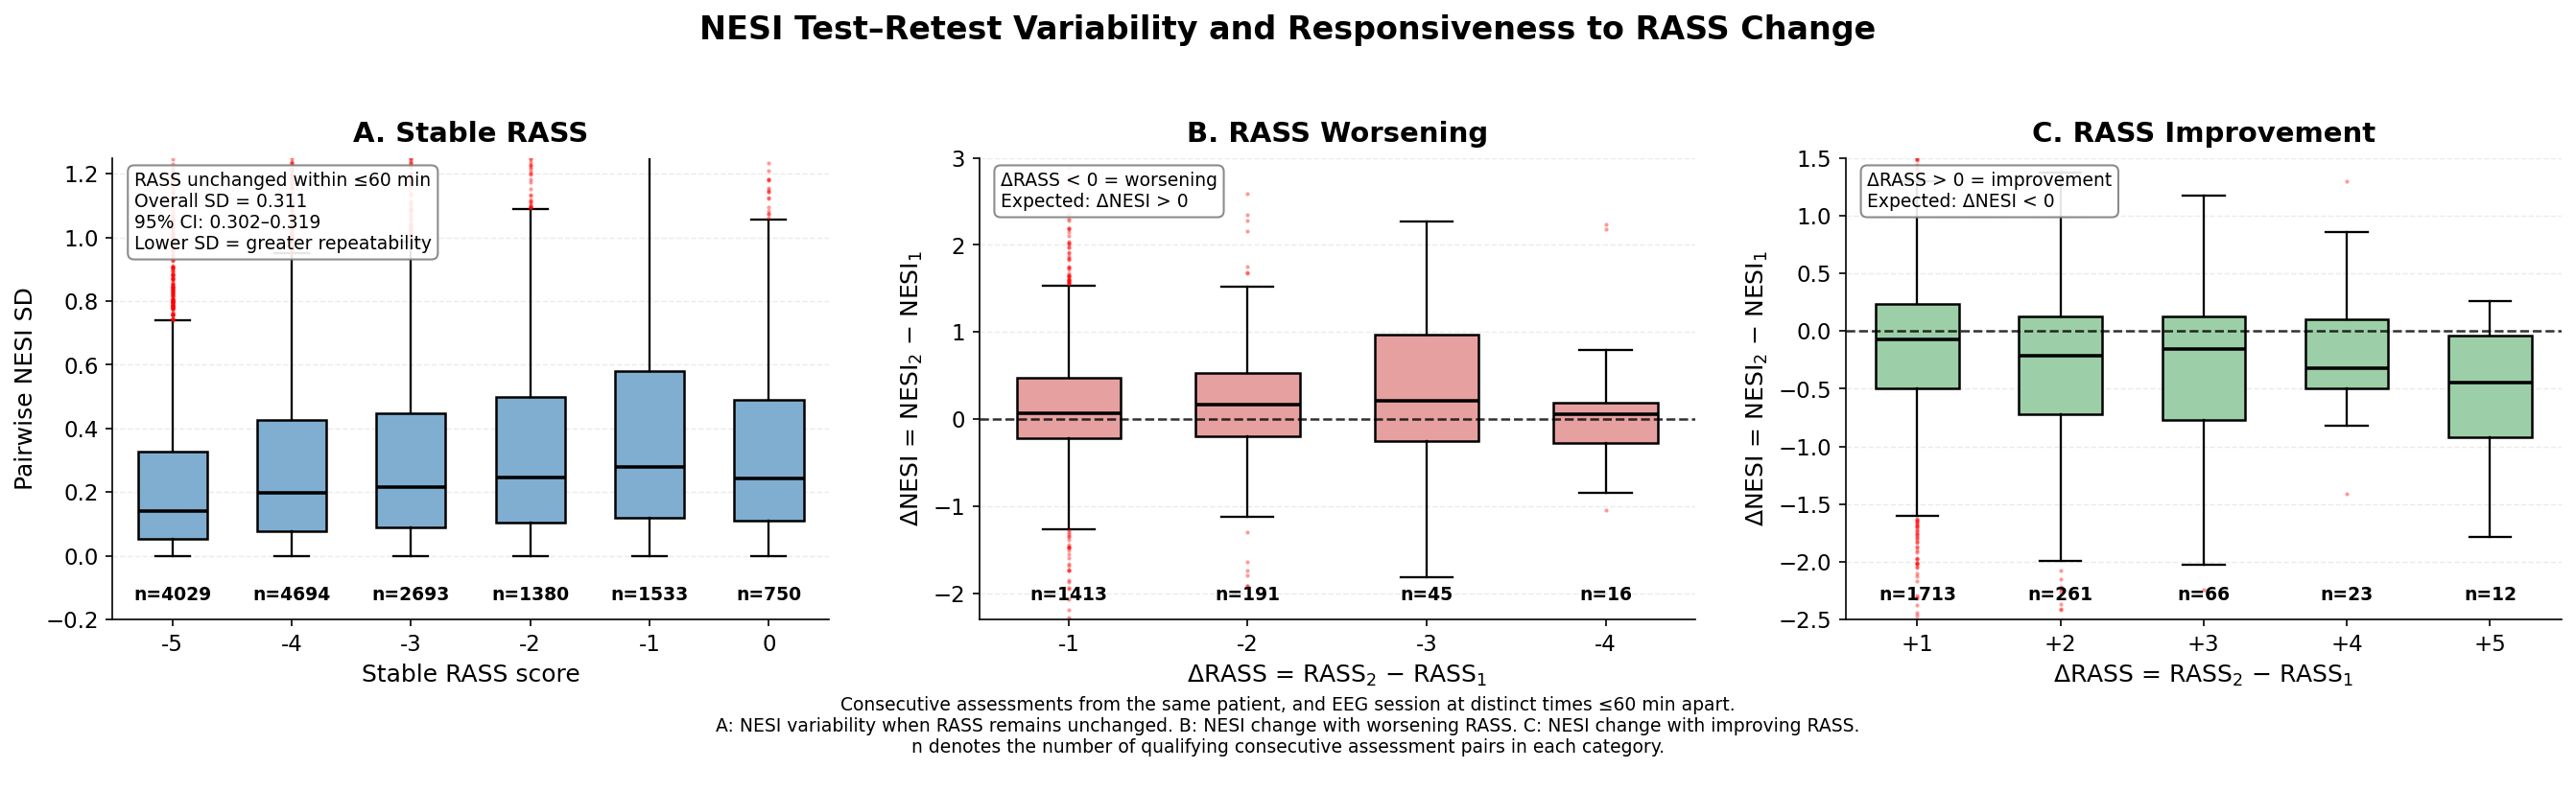


===== NESI MINIMAL DETECTABLE CHANGE (MDC95) =====
   RASS  Patients  Pairs  Mean ΔNESI  SD ΔNESI   SEM  MDC95  95% CI Lower  95% CI Upper
Overall      1754  15079       0.000     0.644 0.455  1.262         1.228         1.297
     -5       482   4029      -0.005     0.555 0.393  1.088         1.023         1.145
     -4       740   4694       0.003     0.642 0.454  1.258         1.202         1.313
     -3       624   2693      -0.005     0.637 0.450  1.248         1.185         1.315
     -2       436   1380       0.003     0.679 0.480  1.331         1.239         1.417
     -1       484   1533      -0.002     0.789 0.558  1.546         1.459         1.636
      0       292    750       0.030     0.725 0.512  1.420         1.273         1.578


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_nesi_rass_3panel(df_NESI_RASS,split="all",plot_type="box",save_path=None,
                          max_interval_min=60,n_boot=5000,seed=42,figsize=(18,5.5),
                          dpi=150,save_dpi=500,ylim_A=(-0.05,1.25),
                          ylim_B=(-1.5,1.75),ylim_C=(-2.0,1.5)):
    df=df_NESI_RASS.copy()
    required=["BDSPPatientID","BidsFolder","SessionID","RASSRecordedDTS","RawScore","NESI"]
    missing=[c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    split=str(split).lower().strip()
    plot_type=str(plot_type).lower().strip()
    if split not in ["all","train","val","test"]:
        raise ValueError("split must be 'all', 'train', 'val', or 'test'")
    if plot_type not in ["box","violin"]:
        raise ValueError("plot_type must be 'box' or 'violin'")
    if split!="all":
        if "Split" not in df.columns:
            raise ValueError("Split column not found.")
        df=df[df["Split"].astype(str).str.lower().str.strip()==split].copy()
    if len(df)==0:
        raise ValueError(f"No rows available for split='{split}'.")
    df["BDSPPatientID"]=df["BDSPPatientID"].astype(str).str.strip()
    df["BidsFolder"]=df["BidsFolder"].astype(str).str.strip()
    df["SessionID"]=pd.to_numeric(df["SessionID"],errors="coerce")
    df["RASSRecordedDTS"]=pd.to_datetime(df["RASSRecordedDTS"],errors="coerce")
    df["RawScore"]=pd.to_numeric(df["RawScore"],errors="coerce")
    df["NESI"]=pd.to_numeric(df["NESI"],errors="coerce")
    df=df.dropna(subset=required).copy()
    df=df[df["RawScore"].isin([-5,-4,-3,-2,-1,0])].copy()
    group_cols=["BDSPPatientID","BidsFolder","SessionID"]
    df=df.sort_values(group_cols+["RASSRecordedDTS"]).reset_index(drop=True)

    pairs=[]
    for key,g in df.groupby(group_cols,sort=False):
        g=g.sort_values("RASSRecordedDTS").reset_index(drop=True)
        for i in range(len(g)-1):
            a=g.iloc[i]
            b=g.iloc[i+1]
            dt=(b["RASSRecordedDTS"]-a["RASSRecordedDTS"]).total_seconds()/60
            if not (0<dt<=max_interval_min):
                continue
            pairs.append({
                "BDSPPatientID":key[0],
                "BidsFolder":key[1],
                "SessionID":key[2],
                "Time1":a["RASSRecordedDTS"],
                "Time2":b["RASSRecordedDTS"],
                "TimeDiff_min":dt,
                "RASS1":a["RawScore"],
                "RASS2":b["RawScore"],
                "NESI1":a["NESI"],
                "NESI2":b["NESI"],
                "Delta_RASS":b["RawScore"]-a["RawScore"],
                "Delta_NESI":b["NESI"]-a["NESI"]
            })
    df_pairs=pd.DataFrame(pairs)
    if len(df_pairs)==0:
        raise RuntimeError(f"No consecutive observations within <= {max_interval_min} min.")

    df_stable=df_pairs[df_pairs["Delta_RASS"]==0].copy()
    df_stable["Stable_RASS"]=df_stable["RASS1"]
    df_stable["NESI_SD"]=df_stable[["NESI1","NESI2"]].std(axis=1,ddof=1)

    def patient_bootstrap_mean(data,value_col):
        d=data[["BDSPPatientID",value_col]].dropna().copy()
        observed=d[value_col].mean()
        patients=d["BDSPPatientID"].unique()
        patient_values={p:d.loc[d["BDSPPatientID"]==p,value_col].values for p in patients}
        rng=np.random.default_rng(seed)
        boot=[]
        for _ in range(n_boot):
            sampled=rng.choice(patients,size=len(patients),replace=True)
            values=np.concatenate([patient_values[p] for p in sampled])
            boot.append(np.mean(values))
        lo,hi=np.percentile(boot,[2.5,97.5])
        return observed,lo,hi

    overall_sd,overall_sd_lo,overall_sd_hi=patient_bootstrap_mean(df_stable,"NESI_SD")
    df_worsening=df_pairs[df_pairs["Delta_RASS"]<0].copy()
    df_improvement=df_pairs[df_pairs["Delta_RASS"]>0].copy()

    print("="*80)
    print(f"NESI-RASS ANALYSIS | SPLIT: {split.upper()}")
    print("="*80)
    print(f"Input rows             : {len(df)}")
    print(f"Unique patients        : {df['BDSPPatientID'].nunique()}")
    print(f"All <=1-h pairs        : {len(df_pairs)}")
    print(f"Stable pairs           : {len(df_stable)}")
    print(f"Worsening pairs        : {len(df_worsening)}")
    print(f"Improvement pairs      : {len(df_improvement)}")
    print(f"Overall stable NESI SD : {overall_sd:.3f} (95% CI {overall_sd_lo:.3f}–{overall_sd_hi:.3f})")

    print("\nA. STABLE RASS — NESI SD")
    print(df_stable.groupby("Stable_RASS")["NESI_SD"].agg(["count","mean","median","std"]).round(3))
    print("\nB. RASS WORSENING — DELTA NESI")
    print(df_worsening.groupby("Delta_RASS")["Delta_NESI"].agg(["count","mean","median","std"]).round(3))
    print("\nC. RASS IMPROVEMENT — DELTA NESI")
    print(df_improvement.groupby("Delta_RASS")["Delta_NESI"].agg(["count","mean","median","std"]).round(3))

    def draw_distribution(ax,data,x_col,y_col,categories,color,title,xlabel,ylabel,
                          ylim=None,zero_line=False,positive_labels=False):
        values=[data.loc[data[x_col]==c,y_col].dropna().values for c in categories]
        counts=[len(v) for v in values]
        positions=np.arange(len(categories))
        if plot_type=="box":
            vals=[v if len(v)>0 else np.array([np.nan]) for v in values]
            ax.boxplot(
                vals,positions=positions,widths=.58,patch_artist=True,showfliers=True,whis=1.5,
                boxprops=dict(facecolor=color,edgecolor="black",linewidth=1.2),
                medianprops=dict(color="black",linewidth=1.7),
                whiskerprops=dict(color="black",linewidth=1.1),
                capprops=dict(color="black",linewidth=1.1),
                flierprops=dict(marker="o",markersize=2,markerfacecolor="red",
                                markeredgecolor="red",markeredgewidth=0,alpha=.40)
            )
        else:
            for pos,v in zip(positions,values):
                if len(v)==0:
                    continue
                vp=ax.violinplot([v],positions=[pos],widths=.72,showmeans=False,
                                 showmedians=False,showextrema=False)
                for body in vp["bodies"]:
                    body.set_facecolor(color)
                    body.set_edgecolor("black")
                    body.set_linewidth(1)
                    body.set_alpha(.75)
                q1,med,q3=np.percentile(v,[25,50,75])
                ax.vlines(pos,q1,q3,color="black",linewidth=5,zorder=3)
                ax.hlines(med,pos-.12,pos+.12,color="white",linewidth=2.2,zorder=4)
        if zero_line:
            ax.axhline(0,color="black",linestyle="--",linewidth=1.2,alpha=.8)
        labels=[f"+{int(c)}" if positive_labels and c>0 else str(int(c)) for c in categories]
        ax.set_xticks(positions)
        ax.set_xticklabels(labels,fontsize=11)
        ax.set_xlabel(xlabel,fontsize=12)
        ax.set_ylabel(ylabel,fontsize=12)
        ax.set_title(title,fontsize=14,fontweight="bold",pad=8)
        ax.tick_params(axis="y",labelsize=11)
        ax.yaxis.grid(True,linestyle="--",linewidth=.7,alpha=.25)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        if ylim is not None:
            ax.set_ylim(ylim)
        ymin,ymax=ax.get_ylim()
        yrange=ymax-ymin
        for pos,n in zip(positions,counts):
            ax.text(pos,ymin+.035*yrange,f"n={n}",ha="center",va="bottom",
                    fontsize=9,fontweight="bold")

    stable_order=[-5,-4,-3,-2,-1,0]
    worsening_order=[-1,-2,-3,-4]
    improvement_order=[1,2,3,4,5]
    fig,axes=plt.subplots(1,3,figsize=figsize,dpi=dpi)

    draw_distribution(
        axes[0],df_stable,"Stable_RASS","NESI_SD",stable_order,"#7FAED0",
        "A. Stable RASS","Stable RASS score","Pairwise NESI SD",ylim=ylim_A
    )
    axes[0].text(
        .03,.97,
        f"RASS unchanged within ≤{max_interval_min} min\n"
        f"Overall SD = {overall_sd:.3f}\n"
        f"95% CI: {overall_sd_lo:.3f}–{overall_sd_hi:.3f}\n"
        "Lower SD = greater repeatability",
        transform=axes[0].transAxes,ha="left",va="top",fontsize=9,
        bbox=dict(boxstyle="round,pad=.35",facecolor="white",edgecolor="gray",alpha=.90)
    )

    draw_distribution(
        axes[1],df_worsening,"Delta_RASS","Delta_NESI",worsening_order,"#E6A0A0",
        "B. RASS Worsening",
        r"$\Delta$RASS = RASS$_2$ − RASS$_1$",
        r"$\Delta$NESI = NESI$_2$ − NESI$_1$",
        ylim=ylim_B,zero_line=True
    )
    axes[1].text(
        .03,.97,
        "ΔRASS < 0 = worsening\n"
        "Expected: ΔNESI > 0",
        transform=axes[1].transAxes,ha="left",va="top",fontsize=9,
        bbox=dict(boxstyle="round,pad=.35",facecolor="white",edgecolor="gray",alpha=.90)
    )

    draw_distribution(
        axes[2],df_improvement,"Delta_RASS","Delta_NESI",improvement_order,"#9CCFA7",
        "C. RASS Improvement",
        r"$\Delta$RASS = RASS$_2$ − RASS$_1$",
        r"$\Delta$NESI = NESI$_2$ − NESI$_1$",
        ylim=ylim_C,zero_line=True,positive_labels=True
    )
    axes[2].text(
        .03,.97,
        "ΔRASS > 0 = improvement\n"
        "Expected: ΔNESI < 0",
        transform=axes[2].transAxes,ha="left",va="top",fontsize=9,
        bbox=dict(boxstyle="round,pad=.35",facecolor="white",edgecolor="gray",alpha=.90)
    )

    split_title="All Data" if split=="all" else f"{split.capitalize()} Split"
    fig.suptitle(
        "NESI Test–Retest Variability and Responsiveness to RASS Change",
        fontsize=16,fontweight="bold",y=.98
    )
    fig.text(
        .5,.015,
        f"Consecutive assessments from the same patient, and EEG session at distinct times ≤{max_interval_min} min apart.\n "
        "A: NESI variability when RASS remains unchanged. "
        "B: NESI change with worsening RASS. "
        "C: NESI change with improving RASS. \n"
        "n denotes the number of qualifying consecutive assessment pairs in each category.\n",
        ha="center",va="bottom",fontsize=9
    )
    plt.tight_layout(rect=[0,.10,1,.94],w_pad=2.5)
    if save_path is not None:
        plt.savefig(save_path,dpi=save_dpi,bbox_inches="tight")
        print(f"\nFigure saved to: {save_path}")
    plt.show()

    return {
        "df_pairs":df_pairs,
        "df_stable":df_stable,
        "df_worsening":df_worsening,
        "df_improvement":df_improvement,
        "overall_sd":overall_sd,
        "overall_sd_ci":(overall_sd_lo,overall_sd_hi)
    }

def calculate_mdc95(df_stable,n_boot=1000,seed=42):
    df=df_stable.copy()
    df["Delta_NESI"]=pd.to_numeric(df["Delta_NESI"],errors="coerce")
    df=df.dropna(subset=["BDSPPatientID","Stable_RASS","Delta_NESI"])
    rng=np.random.default_rng(seed)
    results=[]

    for label,d in [("Overall",df)]+[(str(r),df[df["Stable_RASS"]==r]) for r in [-5,-4,-3,-2,-1,0]]:
        if len(d)<2:
            continue
        diff=d["Delta_NESI"].to_numpy()
        sd_diff=np.std(diff,ddof=1)
        sem=sd_diff/np.sqrt(2)
        mdc95=1.96*np.sqrt(2)*sem
        groups=[g["Delta_NESI"].to_numpy() for _,g in d.groupby("BDSPPatientID",sort=False)]
        n_patients=len(groups)
        boot=[]

        for _ in range(n_boot):
            idx=rng.integers(0,n_patients,n_patients)
            sample=np.concatenate([groups[i] for i in idx])
            if len(sample)>1:
                boot.append(1.96*np.std(sample,ddof=1))

        ci=np.percentile(boot,[2.5,97.5]) if boot else [np.nan,np.nan]
        results.append({
            "RASS":label,
            "Patients":n_patients,
            "Pairs":len(d),
            "Mean ΔNESI":np.mean(diff),
            "SD ΔNESI":sd_diff,
            "SEM":sem,
            "MDC95":mdc95,
            "95% CI Lower":ci[0],
            "95% CI Upper":ci[1]
        })

    return pd.DataFrame(results)

results=plot_nesi_rass_3panel(
    df_NESI_RASS=df_NESI_RASS,
    split="train",
    plot_type="box",
    save_path=None,
    max_interval_min=60,
    ylim_A=(-0.2,1.25),
    ylim_B=(-2.3,3),
    ylim_C=(-2.5,1.5)
)

df_mdc95=calculate_mdc95(results["df_stable"],n_boot=1000,seed=42)

print("\n===== NESI MINIMAL DETECTABLE CHANGE (MDC95) =====")
print(df_mdc95.round(3).to_string(index=False))


===== PATIENT-WEIGHTED STABLE-RASS SD AND MDC95 =====
   RASS  Patients  Stable periods  Mean SD  SD CI low  SD CI high   SEM  MDC95  MDC CI low  MDC CI high
Overall      1754            9087    0.352      0.339       0.366 0.507  1.404       1.355        1.461
     -5       482            2229    0.283      0.261       0.305 0.427  1.183       1.087        1.276
     -4       740            2757    0.344      0.321       0.366 0.511  1.417       1.317        1.505
     -3       624            1677    0.342      0.319       0.364 0.479  1.329       1.241        1.415
     -2       436             900    0.357      0.328       0.387 0.501  1.387       1.268        1.512
     -1       484            1008    0.405      0.377       0.436 0.563  1.561       1.447        1.684
      0       292             516    0.367      0.333       0.407 0.511  1.417       1.278        1.566

Pairs for panels B/C: worsening=1670, improvement=2075


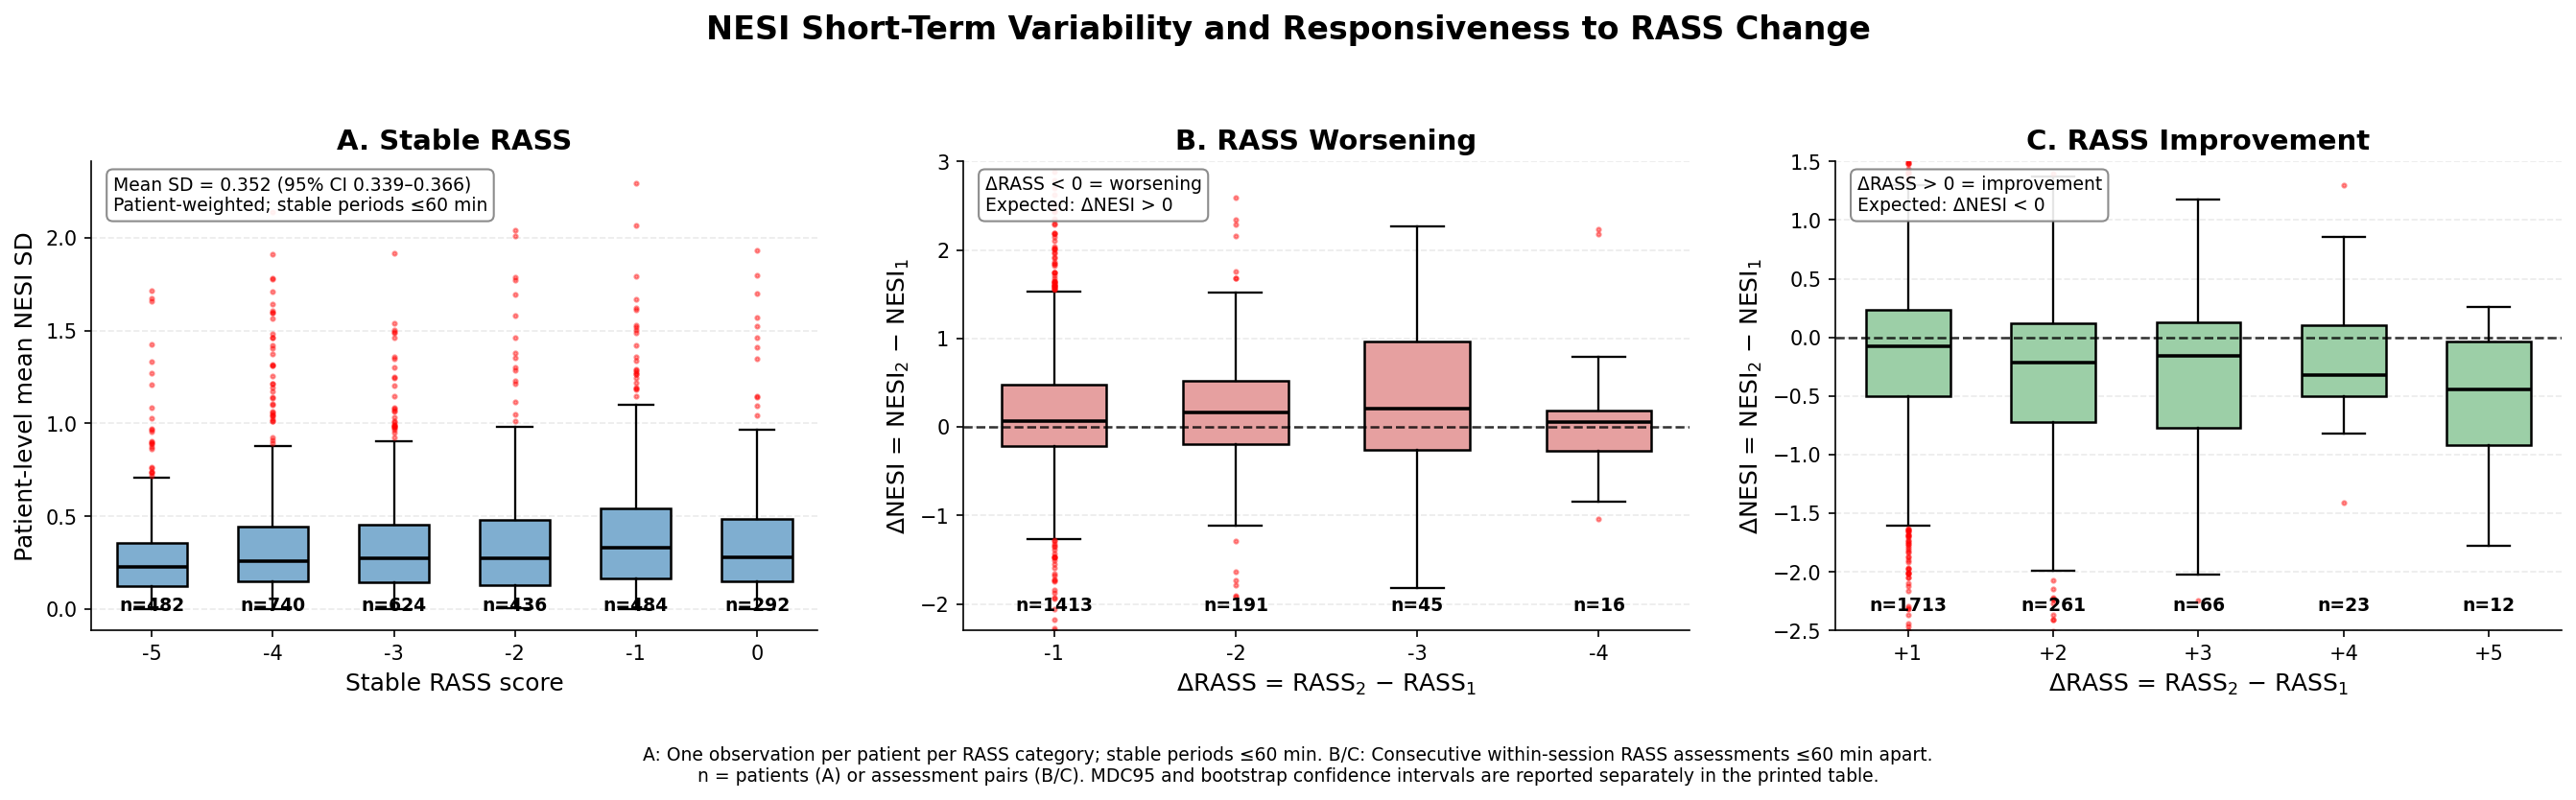

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def plot_nesi_rass_3panel(df_NESI_RASS,split='train',plot_type='box',save_path=None,max_interval_min=60,n_boot=1000,seed=42,figsize=(18,5.5),dpi=150,save_dpi=500,ylim_A=None,ylim_B=(-2.3,3),ylim_C=(-2.5,1.5)):
    d=df_NESI_RASS.copy()
    if split.lower()!='all':
        d=d[d['Split'].astype(str).str.strip().str.lower()==split.lower()].copy()
    keys=['BDSPPatientID','BidsFolder','SessionID']
    required=keys+['RASSRecordedDTS','RawScore','NESI']
    if set(required)-set(d.columns): raise ValueError(f'Missing columns: {set(required)-set(d.columns)}')
    d['BDSPPatientID']=d['BDSPPatientID'].astype(str).str.strip()
    d['RASSRecordedDTS']=pd.to_datetime(d['RASSRecordedDTS'],errors='coerce')
    for c in ['RawScore','NESI','SessionID']: d[c]=pd.to_numeric(d[c],errors='coerce')
    d=d.dropna(subset=required)
    d=d[d['RawScore'].isin([-5,-4,-3,-2,-1,0])].sort_values(keys+['RASSRecordedDTS']+(['Filename'] if 'Filename' in d.columns else [])).reset_index(drop=True)
    g=d.groupby(keys,sort=False)
    dt=(d['RASSRecordedDTS']-g['RASSRecordedDTS'].shift()).dt.total_seconds()/60
    same=(d['RawScore']==g['RawScore'].shift())
    valid=dt.gt(0)&dt.le(max_interval_min)
    pair_mask=valid
    pairs=d.loc[pair_mask,keys+['RawScore','NESI']].copy()
    pairs['RASS1']=g['RawScore'].shift()[pair_mask].to_numpy()
    pairs['NESI1']=g['NESI'].shift()[pair_mask].to_numpy()
    pairs=pairs.rename(columns={'RawScore':'RASS2','NESI':'NESI2'})
    pairs['Delta_RASS']=pairs['RASS2']-pairs['RASS1']
    pairs['Delta_NESI']=pairs['NESI2']-pairs['NESI1']
    worsening=pairs[pairs['Delta_RASS']<0].copy()
    improvement=pairs[pairs['Delta_RASS']>0].copy()
    # Stable runs are split at changes in RASS, gaps, or the 60-min elapsed window limit.
    continuing=valid&same
    run_ids=np.zeros(len(d),dtype=int)
    for _,idx in d.groupby(keys,sort=False).indices.items():
        idx=np.sort(idx); rid=0; start=None
        for j in idx:
            if start is None or not continuing.iloc[j] or (d.at[j,'RASSRecordedDTS']-start).total_seconds()/60>max_interval_min:
                rid+=1; start=d.at[j,'RASSRecordedDTS']
            run_ids[j]=rid
    d['RunID']=run_ids
    run=d.groupby(keys+['RunID'],sort=False).agg(RASS=('RawScore','first'),N=('NESI','size'),SD=('NESI','std')).reset_index()
    run=run[run['N']>=2].copy()
    if run.empty: raise ValueError('No stable periods with at least two NESI observations')
    run['Variance']=run['SD']**2
    patient=run.groupby(['BDSPPatientID','RASS'],as_index=False).agg(Runs=('SD','size'),Mean_SD=('SD','mean'),Mean_Variance=('Variance','mean'))
    overall=run.groupby('BDSPPatientID',as_index=False).agg(Runs=('SD','size'),Mean_SD=('SD','mean'),Mean_Variance=('Variance','mean'))
    rng=np.random.default_rng(seed); rows=[]
    for label,p,r in [('Overall',overall,run)]+[(str(v),patient[patient['RASS']==v],run[run['RASS']==v]) for v in [-5,-4,-3,-2,-1,0]]:
        if p.empty: continue
        s=p['Mean_SD'].to_numpy(); v=p['Mean_Variance'].to_numpy(); n=len(p)
        bs=[]; bm=[]
        for _ in range(n_boot):
            ix=rng.integers(0,n,n)
            bs.append(s[ix].mean()); bm.append(1.96*np.sqrt(2)*np.sqrt(v[ix].mean()))
        rows.append({'RASS':label,'Patients':n,'Stable periods':len(r),'Mean SD':s.mean(),'SD CI low':np.percentile(bs,2.5),'SD CI high':np.percentile(bs,97.5),'SEM':np.sqrt(v.mean()),'MDC95':1.96*np.sqrt(2)*np.sqrt(v.mean()),'MDC CI low':np.percentile(bm,2.5),'MDC CI high':np.percentile(bm,97.5)})
    summary=pd.DataFrame(rows)
    print('\n===== PATIENT-WEIGHTED STABLE-RASS SD AND MDC95 =====')
    print(summary.round(3).to_string(index=False))
    print(f'\nPairs for panels B/C: worsening={len(worsening)}, improvement={len(improvement)}')
    fig,axes=plt.subplots(1,3,figsize=figsize,dpi=dpi)
    def draw(ax,values,labels,color,title,xlabel,ylabel,ylim,zero=False):
        positions=np.arange(len(labels)); vals=[v if len(v) else np.array([np.nan]) for v in values]
        if plot_type=='box':
            ax.boxplot(vals,positions=positions,widths=.58,patch_artist=True,showfliers=True,whis=1.5,
                       boxprops=dict(facecolor=color,edgecolor='black',linewidth=1.2),medianprops=dict(color='black',linewidth=1.7),
                       whiskerprops=dict(color='black',linewidth=1.1),capprops=dict(color='black',linewidth=1.1),
                       flierprops=dict(marker='o',markersize=2,markerfacecolor='red',markeredgecolor='red',alpha=.4))
        elif plot_type=='violin':
            for pos,v in zip(positions,values):
                if len(v)<2: continue
                vp=ax.violinplot([v],positions=[pos],widths=.72,showmedians=True,showextrema=False)
                for body in vp['bodies']: body.set_facecolor(color); body.set_edgecolor('black'); body.set_alpha(.75)
        else: raise ValueError("plot_type must be 'box' or 'violin'")
        if zero: ax.axhline(0,color='black',ls='--',lw=1.2,alpha=.8)
        ax.set_xticks(positions,labels); ax.set_title(title,fontsize=14,fontweight='bold'); ax.set_xlabel(xlabel,fontsize=12); ax.set_ylabel(ylabel,fontsize=12)
        ax.grid(axis='y',ls='--',alpha=.25); ax.set_axisbelow(True)
        for side in ['top','right']: ax.spines[side].set_visible(False)
        if ylim is not None: ax.set_ylim(ylim)
        ymin,ymax=ax.get_ylim()
        for pos,v in zip(positions,values): ax.text(pos,ymin+.035*(ymax-ymin),f'n={len(v)}',ha='center',va='bottom',fontsize=9,fontweight='bold')
    cats=[-5,-4,-3,-2,-1,0]
    draw(axes[0],[patient.loc[patient['RASS']==r,'Mean_SD'].to_numpy() for r in cats],[str(r) for r in cats],'#7FAED0','A. Stable RASS','Stable RASS score','Patient-level mean NESI SD',ylim_A)
    overall_row=summary.iloc[0]
    axes[0].text(.03,.97,f"Mean SD = {overall_row['Mean SD']:.3f} (95% CI {overall_row['SD CI low']:.3f}–{overall_row['SD CI high']:.3f})\nPatient-weighted; stable periods ≤{max_interval_min} min",transform=axes[0].transAxes,ha='left',va='top',fontsize=9,bbox=dict(boxstyle='round,pad=.35',facecolor='white',edgecolor='gray',alpha=.9))
    wc=[-1,-2,-3,-4]; ic=[1,2,3,4,5]
    draw(axes[1],[worsening.loc[worsening['Delta_RASS']==r,'Delta_NESI'].to_numpy() for r in wc],[str(r) for r in wc],'#E6A0A0','B. RASS Worsening',r'$\Delta$RASS = RASS$_2$ − RASS$_1$',r'$\Delta$NESI = NESI$_2$ − NESI$_1$',ylim_B,True)
    axes[1].text(.03,.97,'ΔRASS < 0 = worsening\nExpected: ΔNESI > 0',transform=axes[1].transAxes,ha='left',va='top',fontsize=9,bbox=dict(boxstyle='round,pad=.35',facecolor='white',edgecolor='gray',alpha=.9))
    draw(axes[2],[improvement.loc[improvement['Delta_RASS']==r,'Delta_NESI'].to_numpy() for r in ic],[f'+{r}' for r in ic],'#9CCFA7','C. RASS Improvement',r'$\Delta$RASS = RASS$_2$ − RASS$_1$',r'$\Delta$NESI = NESI$_2$ − NESI$_1$',ylim_C,True)
    axes[2].text(.03,.97,'ΔRASS > 0 = improvement\nExpected: ΔNESI < 0',transform=axes[2].transAxes,ha='left',va='top',fontsize=9,bbox=dict(boxstyle='round,pad=.35',facecolor='white',edgecolor='gray',alpha=.9))
    fig.suptitle('NESI Short-Term Variability and Responsiveness to RASS Change',fontsize=16,fontweight='bold',y=.99)
    fig.text(.5,.015,f'A: One observation per patient per RASS category; stable periods ≤{max_interval_min} min. B/C: Consecutive within-session RASS assessments ≤{max_interval_min} min apart.\nn = patients (A) or assessment pairs (B/C). MDC95 and bootstrap confidence intervals are reported separately in the printed table.',ha='center',va='bottom',fontsize=9)
    plt.tight_layout(rect=[0,.10,1,.94],w_pad=2.5)
    if save_path is not None: plt.savefig(save_path,dpi=save_dpi,bbox_inches='tight')
    plt.show()
    return {'summary':summary,'patient_stats':patient,'stable_periods':run,'df_pairs':pairs,'df_worsening':worsening,'df_improvement':improvement}

if __name__=='__main__':
    df_NESI_RASS=pd.read_csv('/home/ayush/Desktop/NESI_review_material/MDC_analysis/MDC_Data_RASS_GCS/RASS_MDC_ExptMetadata.csv')
    results=plot_nesi_rass_3panel(df_NESI_RASS,split='train',plot_type='box',save_path=None,max_interval_min=60,n_boot=1000,seed=42,ylim_A=None,ylim_B=(-2.3,3),ylim_C=(-2.5,1.5))
